In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.sans-serif'] = ['SimHei']
rcParams['axes.unicode_minus'] = False
import seaborn as sns
#将数据输出结果导出
import os


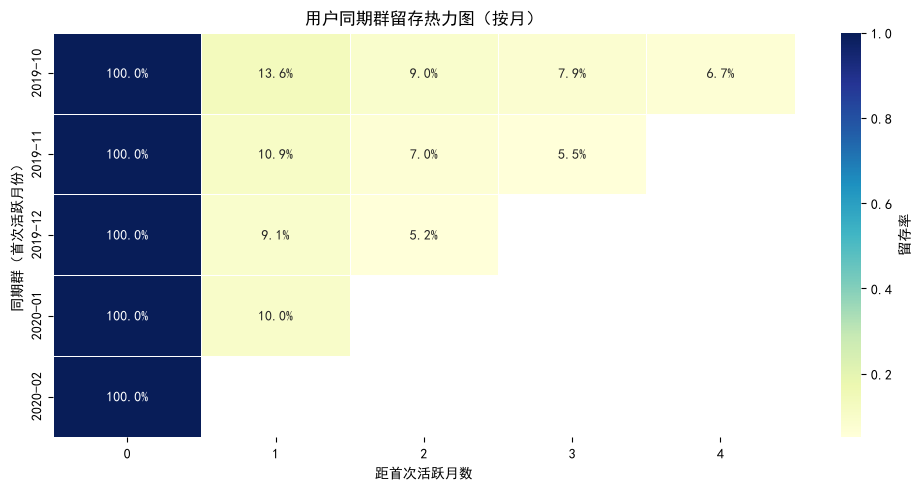

 同期群留存分析结果
留存率矩阵（行=首次活跃月份，列=距首次活跃月数）：
month_offset    0       1       2       3       4
first_month                                      
2019-10       1.0  0.1359  0.0900  0.0786  0.0668
2019-11       1.0  0.1089  0.0695  0.0551     NaN
2019-12       1.0  0.0914  0.0518     NaN     NaN
2020-01       1.0  0.1005     NaN     NaN     NaN
2020-02       1.0     NaN     NaN     NaN     NaN
------------------------------
各同期群首月活跃用户数：
first_month
2019-10    398794.0
2019-11    313154.0
2019-12    299076.0
2020-01    328563.0
2020-02    297526.0


In [4]:
df=pd.read_csv('out_data/allmonth_clean.csv')
'''-------------同期群留存分析:按用户首次访问月份分组（同期群），看这群人在后续第 1~N 个月是否还活跃，衡量用户粘性、拉新质量，判断运营活动是否有长效价值。-------------'''

# 1. 统一日期格式，并取出月份
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.to_period('M')

# 2. 单独聚合每个用户的首次活跃月份（生成实体表）
user_first = df.groupby('user_id')['month'].min().reset_index()
user_first.columns = ['user_id', 'first_month']

# 3. 左连接回主表（替代transform，生成普通物理列）
df = df.merge(user_first, on='user_id', how='left')

# 4. 计算距离首次活跃的月数
df['month_offset'] = (df['month'] - df['first_month']).apply(lambda x: x.n)

# 5. 构建同期群数据
cohort = df.groupby(['first_month', 'month_offset'])['user_id'].nunique().reset_index()

# 6. 生成透视表
cohort_pivot = cohort.pivot(
    index='first_month',
    columns='month_offset',
    values='user_id'
)
cohort_pivot.columns = cohort_pivot.columns.astype(str)
#  计算留存率（除以第0个月的用户数）
cohort_pivot.index = cohort_pivot.index.astype(str)
cohort_retention = cohort_pivot.divide(cohort_pivot.iloc[:, 0], axis=0)

#  画留存热力图
plt.figure(figsize=(10, 5))
sns.heatmap(cohort_retention, annot=True, fmt='.1%', cmap='YlGnBu',
            annot_kws={'size': 10}, linewidths=0.5, cbar_kws={'label': '留存率'})
plt.title('用户同期群留存热力图（按月）')
plt.xlabel('距首次活跃月数')
plt.ylabel('同期群（首次活跃月份）')
plt.tight_layout()
plt.show()
print(" 同期群留存分析结果")
print("="*50)

# 输出留存率矩阵
print("留存率矩阵（行=首次活跃月份，列=距首次活跃月数）：")
print(cohort_retention.round(4).to_string())
print("-"*30)
print("各同期群首月活跃用户数：")
print(cohort_pivot.iloc[:, 0].to_string())
# ====================== 保存数据用于后续可视化输出 ======================
# 留存率矩阵（重置索引方便读取）
cohort_retention.reset_index().to_csv('output/data/user_retention.csv',
                                      index=False, encoding='utf-8-sig')
